In [1]:
# import cython
import numpy as np
import matplotlib.pyplot as plt 
import glob
import os


In [2]:
from OXmodeCython import OXmode_cython

In [3]:
# Check that MPS is available
import torch
from unet import UNet, TransformerNet
import torchvision.transforms as transforms

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
print(device)

# if not torch.backends.mps.is_available():
#     if not torch.backends.mps.is_built():
#         print("MPS not available because the current PyTorch install was not "
#               "built with MPS enabled.")
#     else:
#         print("MPS not available because the current MacOS version is not 12.3+ "
#               "and/or you do not have an MPS-enabled device on this machine.")

# else:
#     device = torch.device("mps")

cuda:0


In [4]:
def dist_loss(input, model): # radius is the maxmum loss between two points. 
    loss = 0.0
    for point in input:
        error = (np.min(np.sum((model-point)**2, axis = 1)))
        loss += error
    loss = loss/input.shape[0]
    # print(input.shape[0])
    # print(model.shape)
    return loss

In [5]:
target_size = [512,408]
saved_model_dir = 'saved_model/'
savedmodel_list = glob.glob1(saved_model_dir,'TOPHAT_checkpoint_epoch_*')
savedmodel_list.sort()
print(len(savedmodel_list))

testfiles = glob.glob1('VIPIR_PROC/labeled/','*.npy')
testfiles.sort()
evalresult = {}


61


In [6]:
outdir = 'Testfitting_eval_model/'
evalresult = np.load(outdir+'evalresult_file.npy', allow_pickle=True, fix_imports=True)[()]

In [7]:
model = UNet(n_channels=1, n_classes=4, input_size=target_size, in_dropout_p = 0.4, dropout_p=0.4)
model = model.to(device=device)

for f in savedmodel_list[30:]:
    if f in evalresult:
        continue
    state_data = torch.load(saved_model_dir+f, weights_only=True)
    model.load_state_dict(state_data['model_state_dict'])
    model.eval()
    with torch.no_grad():
        mean_loss = 0.0
        checkpoint_result = {}
        for file in testfiles:
            loss = 0.0
            testdata = np.load('VIPIR_PROC/labeled/' + file, allow_pickle=True, fix_imports=True)[()]

            testimage1 = torch.from_numpy(testdata['mask_full']).float()
            testimage1 = testimage1[None,None,:,:]# resize_tr(testimage1[None,None,:,:])
            img = testimage1 #torch.cat([testimage1,XX[None,None,:,:],YY[None,None,:,:]],dim=-3)
            img = img.to('cuda')
            label1 = model(img)
            label1 = label1.squeeze().to('cpu')

            imgO = torch.argmax(label1[0:2,:,:],dim=0).detach().cpu().numpy()
            imgX = torch.argmax(label1[2:4,:,:],dim=0).detach().cpu().numpy()

            Y, X = imgO.nonzero()
            inputO = np.vstack((X,Y)).T

            Y, X = imgX.nonzero()
            inputX = np.vstack((X,Y)).T

            otrace = testdata['otrace']
            Y, X = otrace.nonzero()
            targetO = np.vstack((X,Y)).T

            xtrace = testdata['xtrace']
            Y, X = xtrace.nonzero()
            targetX = np.vstack((X,Y)).T

            loss += dist_loss(inputO, targetO)
            loss += dist_loss(inputX, targetX)
            
            checkpoint_result[file] = loss

            mean_loss += loss
            
            fig, axs = plt.subplots(ncols=4, nrows=1, figsize=(18, 5))
            fig.suptitle(f'{file} loss:{loss}', fontsize=16)

            ax = axs[0]
            ax.imshow(np.log10(testdata['original']), origin='lower', aspect = 'equal')
            ax.axis('off')
            ax.set_title('Original')

            ax = axs[1]
            ax.imshow(testimage1.detach().squeeze(), origin='lower', aspect = 'equal')
            ax.axis('off')
            ax.set_title('Binary')
            
            ax = axs[2]
            ax.imshow(imgO + 2*imgX, origin='lower', aspect = 'equal')
            ax.axis('off')
            ax.set_title('Output Combined')

            ax = axs[3]
            ax.imshow(otrace + 2*xtrace, origin='lower', aspect = 'equal')
            ax.axis('off')
            ax.set_title('GT Combined')

            if not os.path.exists(outdir+f):
                os.makedirs(outdir+f)

            fig.savefig(outdir+f'{f}/{file[:-4]}.png', bbox_inches='tight')
            plt.close()

            del label1; del img
            # print(file)
            # break
        # del model
        del state_data
        np.save(outdir+f'{f}/checkpoint_result.npy', checkpoint_result)
        
        mean_loss = mean_loss/len(testdata)
        evalresult[f] = mean_loss
        print(mean_loss)
        np.save(outdir+f'evalresult_file.npy', evalresult)
        with open(outdir+"evalresult_file.txt", "w") as txt:
            for i in evalresult:
                txt.write(f'{evalresult[i]}, {i}\n')
    # break

1856.1582508385084
1695.6343045661592
1045.7358250741145
757.471215533257
1639.4688747086952
1716.0957925901523
1864.3843112182974
1417.1625571956367
1565.959266107377
1839.2332443792786
1845.808782361773
1855.8883473740727
3372.604269923412
3199.4298767462783
1792.9393036370832
1846.3223452555662
4207.678510353418
3077.6410322900506
3019.9429576261873
2563.8562888534243
3029.7242299005643
2646.6706509292667
3087.058998436631
2629.478164667407
3383.562544143549
2688.8362192924405
2165.6090162888763
2468.0077845372643
2356.8839712606073
2321.4173966587923


In [12]:
# evalresult_filtered = {}
# for k in evalresult:
#     segs = k.split('_')
#     if segs[4] == '36000':
#         continue
#     else:
#         evalresult_filtered[k] = evalresult[k]
print(len(evalresult))

61


['TOPHAT_checkpoint_epoch_10_18000_loss1.3685.pth', 'TOPHAT_checkpoint_epoch_10_36000_loss1.3712.pth', 'TOPHAT_checkpoint_epoch_11_18000_loss1.3510.pth', 'TOPHAT_checkpoint_epoch_11_36000_loss1.3364.pth', 'TOPHAT_checkpoint_epoch_12_18000_loss1.2834.pth', 'TOPHAT_checkpoint_epoch_12_36000_loss1.3403.pth', 'TOPHAT_checkpoint_epoch_13_18000_loss1.3723.pth', 'TOPHAT_checkpoint_epoch_13_36000_loss1.3575.pth', 'TOPHAT_checkpoint_epoch_14_18000_loss1.3561.pth', 'TOPHAT_checkpoint_epoch_14_36000_loss1.3748.pth', 'TOPHAT_checkpoint_epoch_15_18000_loss1.3699.pth', 'TOPHAT_checkpoint_epoch_15_36000_loss1.3770.pth', 'TOPHAT_checkpoint_epoch_16_18000_loss1.3753.pth', 'TOPHAT_checkpoint_epoch_16_36000_loss1.3871.pth', 'TOPHAT_checkpoint_epoch_17_18000_loss1.3632.pth', 'TOPHAT_checkpoint_epoch_17_36000_loss1.3822.pth', 'TOPHAT_checkpoint_epoch_18_18000_loss1.3781.pth', 'TOPHAT_checkpoint_epoch_18_36000_loss1.3809.pth', 'TOPHAT_checkpoint_epoch_19_18000_loss1.3938.pth', 'TOPHAT_checkpoint_epoch_19_36

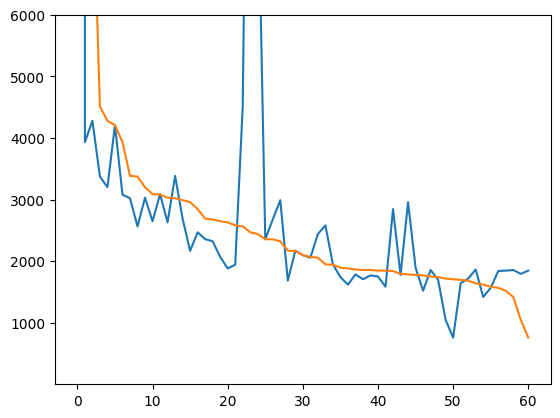

In [13]:
# evalresult = evalresult_filtered
loss = [evalresult[l] for l in evalresult]
filenames = [l for l in evalresult]

# plt.plot(np.log10(loss))
print(filenames)

# temp = sorted(evalresult, key=lambda e : evalresult[e], reverse=True)
def key_func(s: str) -> float:
    segs = s.split('_')
    return float(segs[3])+float(segs[4])/36000

temp1 = sorted(evalresult, key=key_func, reverse=False)
temp2 = sorted(evalresult, key=lambda e : evalresult[e], reverse=True)

print(temp1)
print(temp2)

# print([(t, evalresult[t]) for t in temp])
plt.plot([evalresult[t] for t in temp1])
plt.plot([evalresult[t] for t in temp2])
# plt.plot([key_func(t) for t in temp])
plt.ylim(1,6000)

print(temp2[-3:])

([<matplotlib.axis.XTick at 0x7206807b5910>,
 [Text(0, 0, '0'),
  Text(4, 0, '2'),
  Text(8, 0, '4'),
  Text(12, 0, '6'),
  Text(16, 0, '8'),
  Text(20, 0, '10'),
  Text(24, 0, '12'),
  Text(28, 0, '14')])

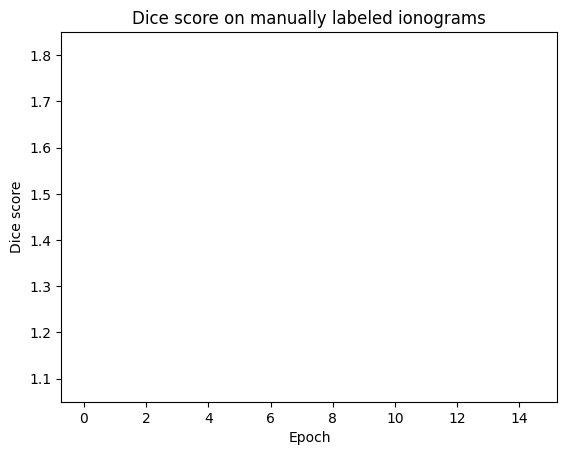

In [10]:
plt.plot([evalresult[t] for t in temp1])
# plt.yscale('log')
plt.ylim(1.05,1.85)
plt.ylabel('Dice score')
plt.xlabel('Epoch')
plt.title('Dice score on manually labeled ionograms')
# plt.xticks(np.arange(0,len(temp2)+1,10),np.arange(0,len(temp2)+1,10)*1000)
plt.xticks(np.arange(0,len(temp2)+1,4),[f'{t:.0f}' for t in np.arange(0,len(temp2)+1,4)*0.5])

In [6]:
from torch.utils.data import DataLoader, random_split
from tqdm import tqdm

from fakeionogramdatasetOX import ParabolaIonoDatasetOX
from testionogramdataset import HandPickTraceDataset

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
print(device)

epochs = 15
batch_size = 5
learning_rate = 1e-5
val_percent = 0.1

weight_decay = 1e-3
momentum = 0.2
gradient_clipping = 1.0

target_size = [512,408] #[572,572] #[524,412]
original_size = [512,408]
resize = 'pad'

train_dataset = ParabolaIonoDatasetOX('training_data', target_size= target_size, resize=resize)

n_val = int(len(train_dataset) * val_percent)
n_train = len(train_dataset) - n_val
train_set, val_set = random_split(train_dataset, [n_train, n_val], generator=torch.Generator())

# 3. Create data loaders
loader_args = dict(batch_size=batch_size,  pin_memory=True) #os.cpu_count()num_workers=5,

train_loader = DataLoader(train_set, shuffle=True, drop_last=True, **loader_args)
val_loader = DataLoader(val_set, shuffle=True, drop_last=True, **loader_args)

test_dataset = HandPickTraceDataset('VIPIR_PROC/labeled', target_size= target_size, resize=resize)
test_loader = DataLoader(test_dataset, shuffle=True, drop_last=True, **loader_args)

cuda:0


In [21]:
def evaluate(net, dataloader, device):
    # net.eval()
    num_val_batches = len(dataloader)

    dice_score = 0
    
    for batch in tqdm(dataloader, total=num_val_batches, desc='Testing round', unit='batch', position=0, leave=True):
        image, label = batch['image'], batch['mask']

        image = image.to(device=device, dtype=torch.float32)
        label = label.to(device=device, dtype=torch.float32)

        m = torch.logical_or(label[:,0,:,:], label[:,1,:,:])

        mask_pred = net(image)
        imgO = torch.argmax(mask_pred[:,0:2,:,:],dim=1)*m
        imgX = torch.argmax(mask_pred[:,2:4,:,:],dim=1)*m
        # imgX = imgO
        # mask_pred = ((imgO + imgX) > 0).float()[:,None,:,:]

        dice_score += dice_coeff(imgO, label[:,0,:,:], reduce_batch_first=False)
        dice_score += dice_coeff(imgX, label[:,1,:,:], reduce_batch_first=False)
        del image; del mask_pred
    # net.train()
    return dice_score / max(num_val_batches, 1)

def dice_coeff(input: torch.Tensor, target: torch.Tensor, reduce_batch_first: bool = False, epsilon: float = 1e-6):
    # Average of Dice coefficient for all batches, or for a single mask
    assert input.size() == target.size()
    assert input.dim() == 3 or not reduce_batch_first

    sum_dim = (-1, -2) if input.dim() == 2 or not reduce_batch_first else (-1, -2, -3)

    inter = 2 * (input * target).sum(dim=sum_dim)
    sets_sum = input.sum(dim=sum_dim) + target.sum(dim=sum_dim)
    sets_sum = torch.where(sets_sum == 0, inter, sets_sum)

    dice = (inter + epsilon) / (sets_sum + epsilon)
    return dice.mean()

In [ ]:
a = torch.tensor([0,0.5,0],dtype=torch.float32)
b = torch.tensor([1,0,0],dtype=torch.float32)
c = torch.logical_or(a,b)
print(c)
print(a,b)
c*torch.tensor([2,2,1])

tensor([ True,  True, False])
tensor([0.0000, 0.5000, 0.0000]) tensor([1., 0., 0.])


tensor([2, 2, 0])

In [22]:
evalresult = {}
model = UNet(n_channels=1, n_classes=4, input_size=target_size, in_dropout_p = 0.35, dropout_p=0.35)
model = model.to(device=device)

for f in savedmodel_list[:]:
    if f in evalresult:
        continue
    state_data = torch.load(saved_model_dir+f,weights_only=True)
    model.load_state_dict(state_data['model_state_dict'])
    model.eval()
    with torch.no_grad():
        test_loss = evaluate(model,test_loader,device)
        del state_data
        evalresult[f] = test_loss.cpu()
        print(evalresult[f])
        
        # np.save(outdir+f'evalresult_file.npy', evalresult)
        # with open(outdir+"evalresult_file.txt", "w") as txt:
        #     for i in evalresult:
        #         txt.write(f'{evalresult[i]}, {i}\n')
    # break

Testing round: 100%|██████████| 40/40 [00:05<00:00,  7.24batch/s]


tensor(1.7837)


Testing round: 100%|██████████| 40/40 [00:05<00:00,  7.26batch/s]


tensor(1.7962)


Testing round: 100%|██████████| 40/40 [00:05<00:00,  7.26batch/s]


tensor(1.7979)


... (112 outputs left out)

Testing round: 100%|██████████| 40/40 [00:05<00:00,  7.14batch/s]


tensor(1.7898)


Testing round: 100%|██████████| 40/40 [00:05<00:00,  7.18batch/s]


tensor(1.7889)


In [ ]:
print(len(train_loader))

/tmp/ipykernel_679907/557938990.py:1: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  data = torch.load('/home/jackle/Documents/MLvipir/saved_model/TOPHAT_checkpoint_epoch_30_

Text(0, 0.5, 'Dice score O+X')

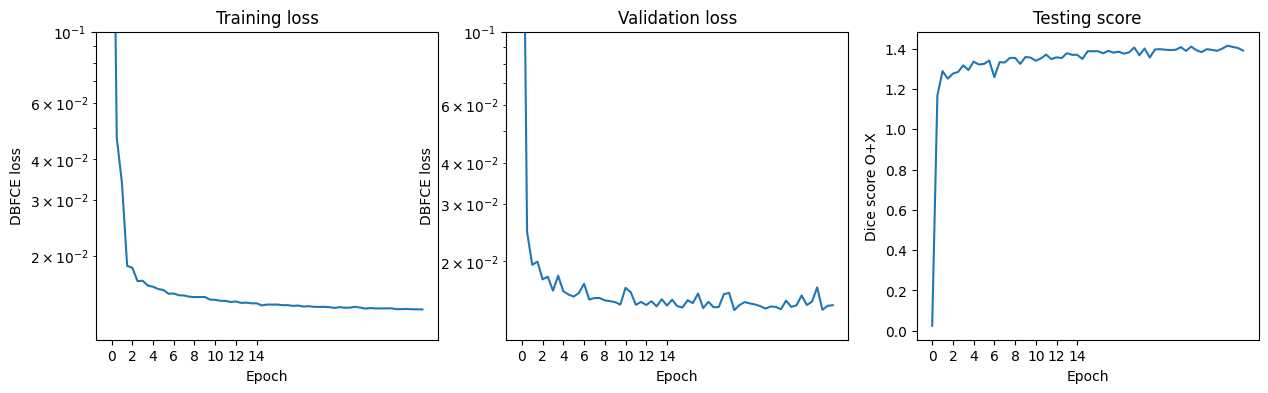

In [12]:
data = torch.load('/home/jackle/Documents/MLvipir/saved_model/TOPHAT_checkpoint_epoch_30_36000_loss1.3915.pth')

test_losses = data['test_loss']
val_losses = data['val_loss']
losses = data['train_loss']

# data = torch.load('saved_model/'+'TOPHAT_checkpoint_epoch_30_25000_loss1.0700.pth')

# test_losses += data['test_loss']
# val_losses += data['val_loss']
# losses += data['train_loss']

fig, axs = plt.subplots(ncols=3, nrows=1, figsize=(15, 4))
ax = axs[0]
ax.plot(losses)
ax.set_xlabel('Epoch')
ax.set_xticks(np.arange(0,len(temp2)+1,4),[f'{t:.0f}' for t in np.arange(0,len(temp2)+1,4)*0.5])
ax.set_ylabel('DBFCE loss')
ax.set_title('Training loss')
ax.set_yscale('log')
ax.set_ylim(0,0.1)
# ax.set_yscale('log')
ax = axs[1]
ax.plot(val_losses)
ax.set_xlabel('Epoch')
ax.set_xticks(np.arange(0,len(temp2)+1,4),[f'{t:.0f}' for t in np.arange(0,len(temp2)+1,4)*0.5])
ax.set_ylabel('DBFCE loss')
ax.set_title('Validation loss')
ax.set_yscale('log')
ax.set_ylim(0,0.1)
# ax.set_yscale('log')
ax = axs[2]
ax.plot(test_losses)
# ax.plot([evalresult[t] for t in temp1])
ax.set_xlabel('Epoch')
ax.set_xticks(np.arange(0,len(temp2)+1,4),[f'{t:.0f}' for t in np.arange(0,len(temp2)+1,4)*0.5])
ax.set_title('Testing score')
ax.set_ylabel('Dice score O+X')
# ax.set_ylim(1.5,1.7)

# ax.set_yscale('log')
# fig.savefig(f'losses.png', bbox_inches='tight')
# plt.close()

In [13]:
# model = UNet(n_channels=3, n_classes=4, up_kernel_size=3)

model = UNet(n_channels=1, n_classes=4, input_size=target_size, in_dropout_p = 0.35, dropout_p=0.35)
# model = TransformerNet(n_channels=1, n_classes=4,input_size=target_size, in_dropout_p = 0.25, dropout_p=0.3)
model.load_state_dict(torch.load('saved_model/new/TOPHAT_checkpoint_epoch_30_18000_loss1.0875.pth')['model_state_dict'])
model = model.to(device=device)
model.eval()

/tmp/ipykernel_679907/265897422.py:5: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load('saved_model/new/TOPHAT_checkpoint_epoch_30_18000_loss1.

FileNotFoundError: [Errno 2] No such file or directory: 'saved_model/new/TOPHAT_checkpoint_epoch_30_18000_loss1.0875.pth'

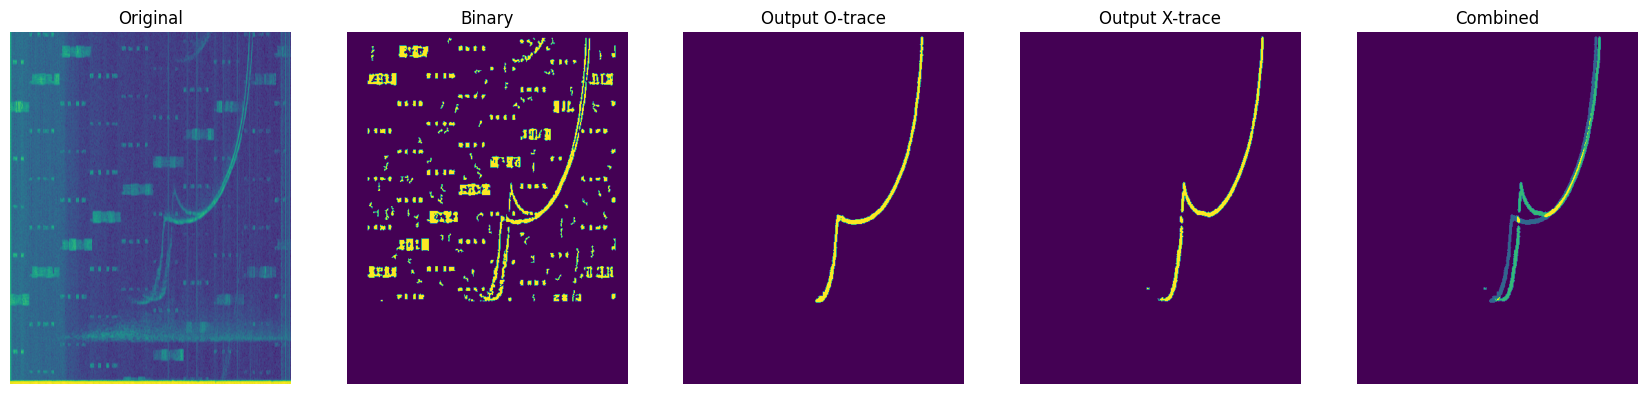

In [38]:
import glob
testfiles = glob.glob1('VIPIR_PROC/proc/','*.npy')
# resize_tr = transforms.Resize((572, 572), antialias = False)

# testim = np.load('VIPIR_PROC/proc/' + testfiles[0], allow_pickle=True, fix_imports=True)[()]
# testim = torch.from_numpy(testim['mask_full']).float()
# XX, YY = torch.meshgrid(torch.linspace(0,1,572,dtype=torch.float32),torch.linspace(0,1,572,dtype=torch.float32))
 
with torch.no_grad():
    
    file = testfiles[np.random.randint(0,len(testfiles)-1)]
    testdata = np.load('VIPIR_PROC/proc/' + file, allow_pickle=True, fix_imports=True)[()]

    testimage1 = torch.from_numpy(testdata['mask_full']).float()
    testimage1 = testimage1[None,None,:,:]# resize_tr(testimage1[None,None,:,:])
    img = testimage1 #torch.cat([testimage1,XX[None,None,:,:],YY[None,None,:,:]],dim=-3)
    img = img.to('cuda')
    label1 = model(img)
    label1 = label1.squeeze().to('cpu')
    # transform = transforms.ToPILImage()
    # img = transform(label1)
    imgO = torch.argmax(label1[0:2,:,:],dim=0).detach().cpu()
    imgX = torch.argmax(label1[2:4,:,:],dim=0).detach().cpu()
    
    fig, axs = plt.subplots(ncols=5, nrows=1, figsize=(21, 7))
    # plt.title(f'epoch{epoch_num}_{file}')

    ax = axs[0]
    ax.imshow(np.log10(testdata['original']), origin='lower', aspect = 'equal')
    ax.axis('off')
    ax.set_title('Original')

    ax = axs[1]
    ax.imshow(testimage1.detach().squeeze(), origin='lower', aspect = 'equal')
    ax.axis('off')
    ax.set_title('Binary')
    
    ax = axs[2]
    ax.imshow(imgO.numpy(), origin='lower', aspect = 'equal')
    ax.axis('off')
    ax.set_title('Output O-trace')

    ax = axs[3]
    ax.imshow(imgX.numpy(), origin='lower', aspect = 'equal')
    ax.axis('off')
    ax.set_title('Output X-trace')

    ax = axs[4]
    ax.imshow(imgO.numpy() + 2*imgX.numpy(), origin='lower', aspect = 'equal')
    ax.axis('off')
    ax.set_title('Combined')
# resize_back = transforms.Resize(ionogram.shape)


In [53]:
model = UNet(n_channels=1, n_classes=4, input_size=target_size, in_dropout_p = 0.4, dropout_p=0.4)
# model = TransformerNet(n_channels=1, n_classes=4,input_size=target_size, in_dropout_p = 0.25, dropout_p=0.3)
model.load_state_dict(torch.load('saved_model/new/TOPHAT_checkpoint_epoch_30_18000_loss1.0875.pth',weights_only=True)['model_state_dict'])
model = model.to(device=device)
model.eval()

testfiles = glob.glob1('VIPIR_PROC/labeled/','*.npy')

with torch.no_grad():
    for file in testfiles:
        dice_score = 0.0
        testdata = np.load('VIPIR_PROC/labeled/' + file, allow_pickle=True, fix_imports=True)[()]

        orgdata = np.load('VIPIR_PROC/org/' + file, allow_pickle=True, fix_imports=True)[()]

        timestruct = orgdata['vipirTimeSct']
        localtime = f"Local time: {timestruct['start_year'][0]:4d}.{timestruct['start_month'][0]:d}.{timestruct['start_day'][0]:d} {timestruct['start_hour'][0]-5:02d}:{timestruct['start_minute'][0]:02d}:{timestruct['start_second'][0]:02d}"


        otrace = torch.from_numpy(testdata['otrace'])[None,None,:,:]
        xtrace = torch.from_numpy(testdata['xtrace'])[None,None,:,:]

        label = torch.stack([otrace,xtrace],dim=1)
        image = torch.from_numpy(testdata['mask_full']).float()
        image = image[None,None,:,:]

        image = image.to(device=device, dtype=torch.float32)
        label = label.to(device=device, dtype=torch.float32)

        m = torch.logical_or(label[:,0,:,:], label[:,1,:,:])

        mask_pred = model(image)
        imgO = torch.argmax(mask_pred[:,0:2,:,:],dim=1)
        imgX = torch.argmax(mask_pred[:,2:4,:,:],dim=1)

        dice_score += dice_coeff(imgO*m, label[:,0,:,:], reduce_batch_first=False)
        dice_score += dice_coeff(imgX*m, label[:,1,:,:], reduce_batch_first=False)      
                
        fig, axs = plt.subplots(ncols=4, nrows=1, figsize=(18, 5))
        fig.suptitle(f'{localtime} Dice score:{dice_score}', fontsize=16)

        ax = axs[0]
        ax.imshow(np.log10(testdata['original']), origin='lower', aspect = 'equal')
        ax.axis('off')
        ax.set_title('Original')

        ax = axs[1]
        ax.imshow(testdata['mask_full'], origin='lower', aspect = 'equal')
        ax.axis('off')
        ax.set_title('Binary')
        
        ax = axs[2]
        ax.imshow(imgO.detach().cpu().squeeze().numpy() + 2*imgX.detach().cpu().squeeze().numpy(), origin='lower', aspect = 'equal')
        ax.axis('off')
        ax.set_title('Output Combined')

        ax = axs[3]
        ax.imshow(testdata['otrace'] + 2*testdata['xtrace'], origin='lower', aspect = 'equal')
        ax.axis('off')
        ax.set_title('GT Combined')

        fig.savefig(outdir+f'/{file[:-4]}.png', bbox_inches='tight')
        plt.close()
        # break
    



In [ ]:


testfiles = glob.glob1('VIPIR_PROC/proc/','*.npy')
# resize_tr = transforms.Resize((572, 572), antialias = False)
# resize_back = transforms.Resize(ionogram.shape)
# testim = np.load('VIPIR_PROC/proc/' + testfiles[0], allow_pickle=True, fix_imports=True)[()]
# testim = torch.from_numpy(testim['mask_full']).float()
# XX, YY = torch.meshgrid(torch.linspace(0,1,572,dtype=torch.float32),torch.linspace(0,1,572,dtype=torch.float32))
 
with torch.no_grad():
    for file in testfiles:
        # file = testfiles[np.random.randint(0,len(testfiles)-1)]
        testdata = np.load('VIPIR_PROC/proc/' + file, allow_pickle=True, fix_imports=True)[()]

        testimage1 = torch.from_numpy(testdata['mask_full']).float()
        # testimage1 = resize_tr(testimage1[None,None,:,:])
        # img = torch.cat([testimage1,XX[None,None,:,:],YY[None,None,:,:]],dim=-3)
        img = testimage1[None,None,:,:]
        img = img.to('cuda')
        label1 = model(img)
        label1 = label1.squeeze().detach().cpu()

        imgO = torch.argmax(label1[0:2,:,:],dim=0)
        imgX = torch.argmax(label1[2:4,:,:],dim=0)
        imgO = imgO[None,:,:].squeeze().numpy() # resize_back(imgO[None,:,:]).squeeze().numpy()
        imgX = imgX[None,:,:].squeeze().numpy() # resize_back(imgX[None,:,:]).squeeze().numpy()
        testimage1 = testimage1.detach().squeeze().numpy()
        
        fig, axs = plt.subplots(ncols=2, nrows=1, figsize=(16, 7))
        plt.title(f'{file}')
        ax = axs[0]
        ax.imshow(testimage1, origin='lower', aspect = 'auto')
        ax.axis('off')
        ax = axs[1]

        ax.imshow(imgO + imgX*2, origin='lower', aspect = 'auto')
        ax.axis('off')

        plt.savefig(f'seg_result_transformer/{file[:-4]}.png', bbox_inches='tight')
        plt.close()

        np.save(f'seg_result_transformer/{file}', {'filename':file, 'image':testimage1, 'imgO': imgO, 'imgX': imgX})

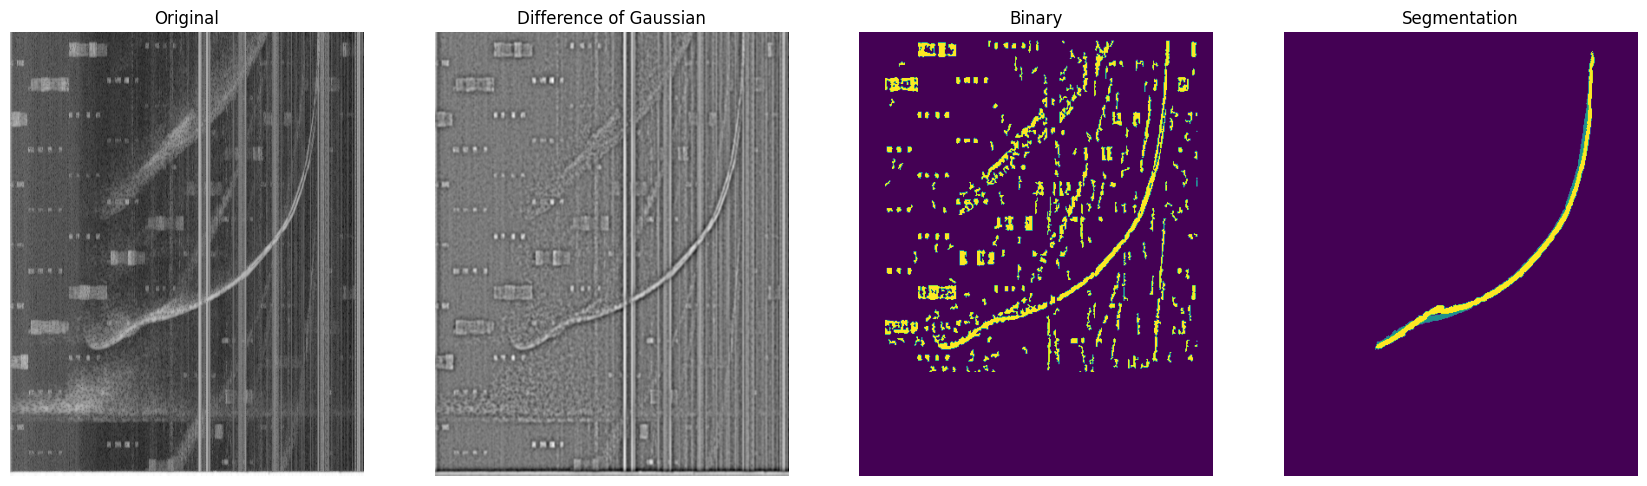

In [54]:
from scipy import ndimage
from skimage import morphology

import glob
testfiles = glob.glob1('VIPIR_PROC/proc/','*.npy')
# resize_tr = transforms.Resize((572, 572), antialias = False)

# testim = np.load('VIPIR_PROC/proc/' + testfiles[0], allow_pickle=True, fix_imports=True)[()]
# testim = torch.from_numpy(testim['mask_full']).float()
# XX, YY = torch.meshgrid(torch.linspace(0,1,572,dtype=torch.float32),torch.linspace(0,1,572,dtype=torch.float32))
 
with torch.no_grad():
    
    file = testfiles[np.random.randint(0,len(testfiles)-1)]
    testdata = np.load('VIPIR_PROC/proc/' + file, allow_pickle=True, fix_imports=True)[()]

    testimage1 = torch.from_numpy(testdata['mask_full']).float()
    testimage1 = testimage1[None,None,:,:]# resize_tr(testimage1[None,None,:,:])
    img = testimage1 #torch.cat([testimage1,XX[None,None,:,:],YY[None,None,:,:]],dim=-3)
    img = img.to('cuda')
    label1 = model(img)
    label1 = label1.squeeze().to('cpu')
    # transform = transforms.ToPILImage()
    # img = transform(label1)
    imgO = torch.argmax(label1[0:2,:,:],dim=0).detach().cpu()
    imgX = torch.argmax(label1[2:4,:,:],dim=0).detach().cpu()
    
    original = testdata['original']
    original -= (np.min(original)-1)
    original[np.isnan(original)] = 1

    temp1 = np.log10(original)

    sigma1 = 0.85
    sigma2 = 3

    gauss1 = ndimage.gaussian_filter(temp1,sigma1)
    gauss2 = ndimage.gaussian_filter(temp1,sigma2)
    out = gauss1-gauss2

    thresh = out > np.percentile(out,80,axis=0)
    
    temp3 = morphology.remove_small_objects(thresh, min_size=20, connectivity=1)
    # structure = np.ones([3,1])
    # temp = ndimage.binary_closing(temp3, structure)

    fig, axs = plt.subplots(ncols=4, nrows=1, figsize=(21, 7))
    # plt.title(f'epoch{epoch_num}_{file}')

    ax = axs[0]
    ax.imshow(np.log10(testdata['original']), origin='lower', aspect = 'equal', cmap='gray')
    ax.axis('off')
    ax.set_title('Original')

    ax = axs[2]
    ax.imshow(testimage1.detach().squeeze(), origin='lower', aspect = 'equal')
    ax.axis('off')
    ax.set_title('Binary')
    
    ax = axs[1]
    ax.imshow(out, origin='lower', aspect = 'equal', cmap='gray')
    ax.axis('off')
    ax.set_title('Difference of Gaussian')

    # ax = axs[3]
    # ax.imshow(imgX.numpy(), origin='lower', aspect = 'equal')
    # ax.axis('off')
    # ax.set_title('Output X-trace')

    ax = axs[3]
    imgO[imgX>0] = 2
    ax.imshow(imgO.numpy(), origin='lower', aspect = 'equal')
    ax.axis('off')
    ax.set_title('Segmentation')

# resize_back = transforms.Resize(ionogram.shape)